In [1]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.8 MB/s eta 0:00:00


In [2]:
import cv2, pickle
import numpy as np
import matplotlib.pyplot as plt
from collections import deque
from google.colab import files
from google.colab.patches import cv2_imshow
from IPython.display import clear_output
from ultralytics import YOLO


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
SPOTS_FILE = "parking_spots.pkl"
MODEL_NAME = "yolov8s-obb.pt"
SCALES = [320, 480, 1024]
CONF = 0.05
NMS_IOU = 0.4
OVERLAP_THR = 0.30
SMOOTH_FRAMES = 7

Saving stock-footage-empty-parking-in-parking-lot-top-view.webm to stock-footage-empty-parking-in-parking-lot-top-view.webm
image size: 898 x 506


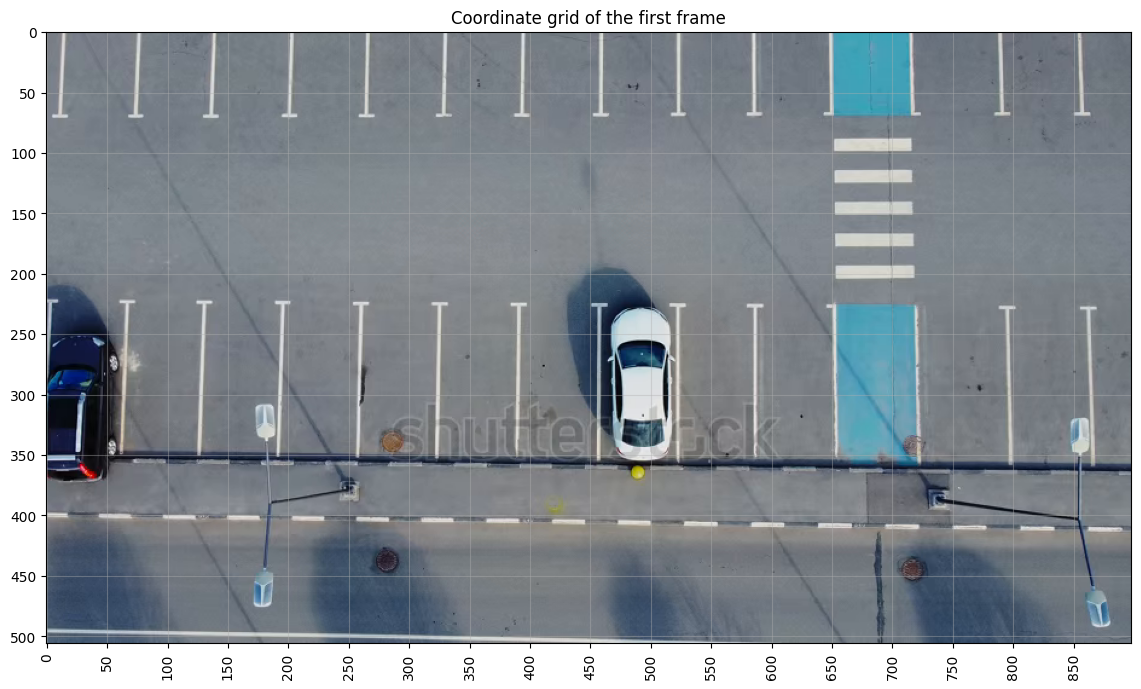

In [4]:
uploaded = files.upload()
path = list(uploaded.keys())[0]
VIDEO_EXT = (".mp4", ".avi", ".mov", ".mkv", ".webm")

if path.lower().endswith(VIDEO_EXT):
    cap = cv2.VideoCapture(path)
    ok, frame0 = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError("Could not read the video")
else:
    frame0 = cv2.imread(path)
    if frame0 is None:
        raise RuntimeError("Could not read the image")

print("image size:", frame0.shape[1], "x", frame0.shape[0])

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(frame0, cv2.COLOR_BGR2RGB))
plt.xticks(range(0, frame0.shape[1], 50), rotation=90)
plt.yticks(range(0, frame0.shape[0], 50))
plt.grid(alpha=0.4)
plt.title("Coordinate grid of the first frame")
plt.show()

W, H = 66 137 | number of spots: 13


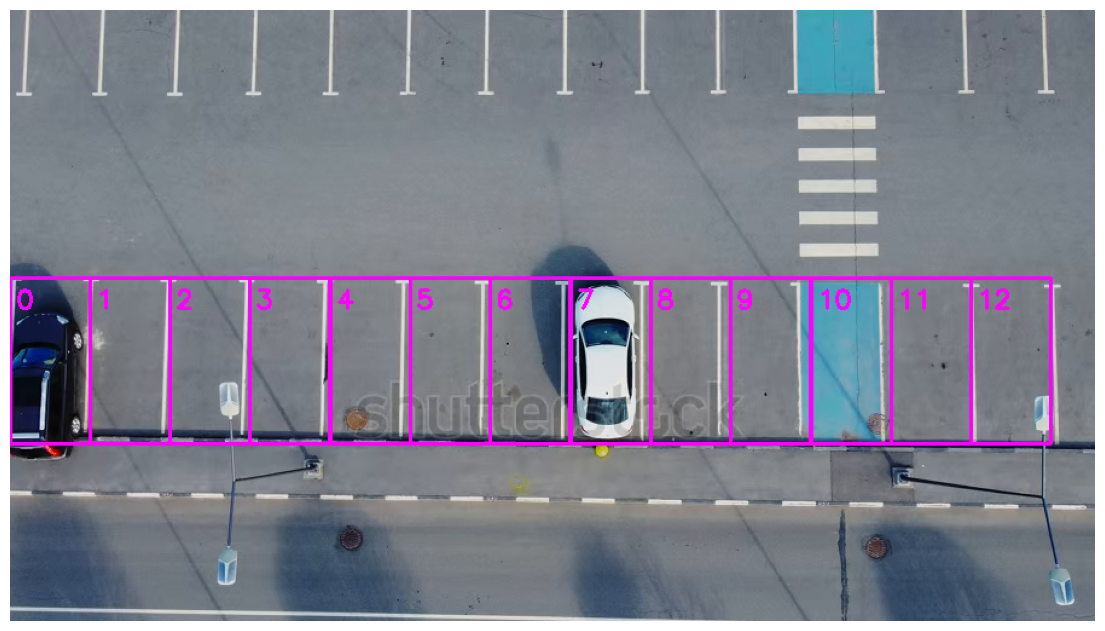

In [5]:
Hf, Wf = frame0.shape[:2]

X_LEFT_FRAC  = 0.00     # left edge of the first spot
X_RIGHT_FRAC = 0.96     # right edge of the last spot
Y_TOP_FRAC   = 0.44     # top of the white lines (bottom row)
Y_BOT_FRAC   = 0.71     # bottom of the white lines
n = 13                  # number of spots in the row

x_left  = int(X_LEFT_FRAC * Wf)
x_right = int(X_RIGHT_FRAC * Wf)
y_top   = int(Y_TOP_FRAC * Hf)
y_bot   = int(Y_BOT_FRAC * Hf)

step = (x_right - x_left) / n
W = int(step)
H = y_bot - y_top

spots = [(int(x_left + i * step), y_top) for i in range(n)]

with open(SPOTS_FILE, "wb") as f:
    pickle.dump(spots, f)
print("W, H =", W, H, "| number of spots:", len(spots))

preview = frame0.copy()
for i, (x, y) in enumerate(spots):
    cv2.rectangle(preview, (x, y), (x + W, y + H), (255, 0, 255), 2)
    cv2.putText(preview, str(i), (x + 5, y + 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 255), 2)

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

Vehicle classes: {9: 'large vehicle', 10: 'small vehicle'}
imgsz=320: 1 vehicles
imgsz=480: 2 vehicles
imgsz=1024: 1 vehicles
Vehicles after merging: 2


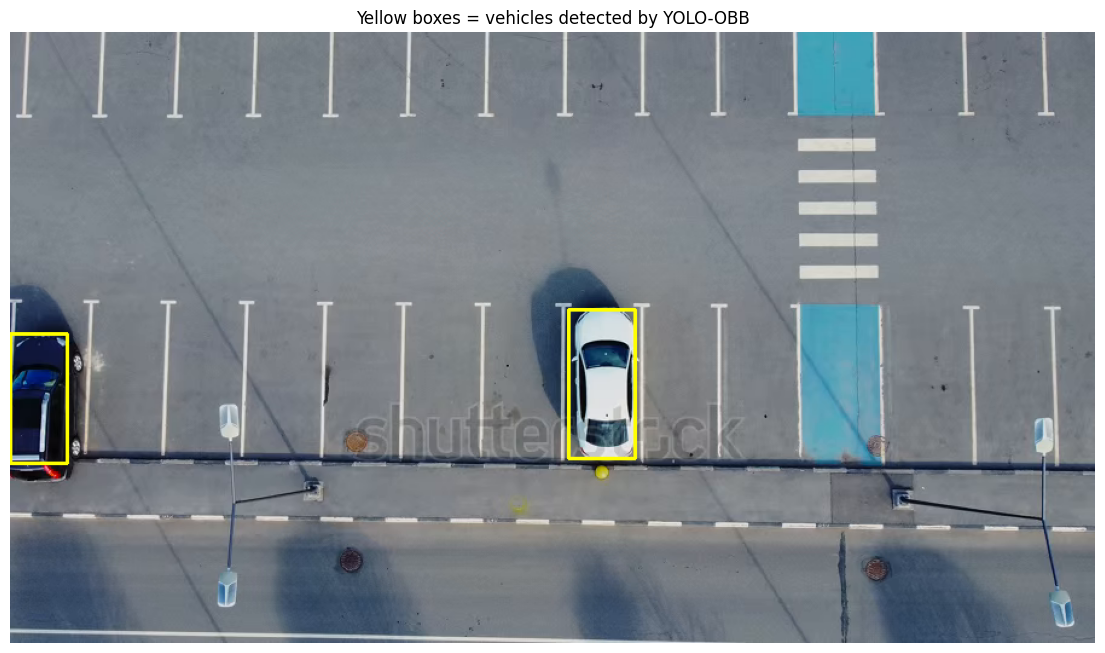

In [6]:
model = YOLO(MODEL_NAME)
VEH_IDS = [i for i, name in model.names.items() if "vehicle" in name]
print("Vehicle classes:", {i: model.names[i] for i in VEH_IDS})

def detect_vehicles(frame):
    boxes, scores = [], []
    for sz in SCALES:
        r = model.predict(frame, conf=CONF, imgsz=sz, verbose=False)[0]
        if r.obb is None or len(r.obb) == 0:
            continue
        xyxy = r.obb.xyxy.cpu().numpy()
        cls = r.obb.cls.cpu().numpy().astype(int)
        conf = r.obb.conf.cpu().numpy()
        for b, c, s in zip(xyxy, cls, conf):
            if c in VEH_IDS:
                boxes.append([int(b[0]), int(b[1]), int(b[2] - b[0]), int(b[3] - b[1])])
                scores.append(float(s))
    if not boxes:
        return np.zeros((0, 4), dtype=int)
    keep = np.array(cv2.dnn.NMSBoxes(boxes, scores, CONF, NMS_IOU)).flatten()
    merged = [[boxes[i][0], boxes[i][1],
               boxes[i][0] + boxes[i][2], boxes[i][1] + boxes[i][3]] for i in keep]
    return np.array(merged, dtype=int)

for sz in SCALES:
    r = model.predict(frame0, conf=CONF, imgsz=sz, verbose=False)[0]
    count = 0 if r.obb is None else sum(int(c) in VEH_IDS for c in r.obb.cls.cpu().numpy())
    print(f"imgsz={sz}: {count} vehicles")

boxes0 = detect_vehicles(frame0)
print("Vehicles after merging:", len(boxes0))

test = frame0.copy()
for (x1, y1, x2, y2) in boxes0:
    cv2.rectangle(test, (x1, y1), (x2, y2), (0, 255, 255), 2)
plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(test, cv2.COLOR_BGR2RGB))
plt.title("Yellow boxes = vehicles detected by YOLO-OBB")
plt.axis("off")
plt.show()

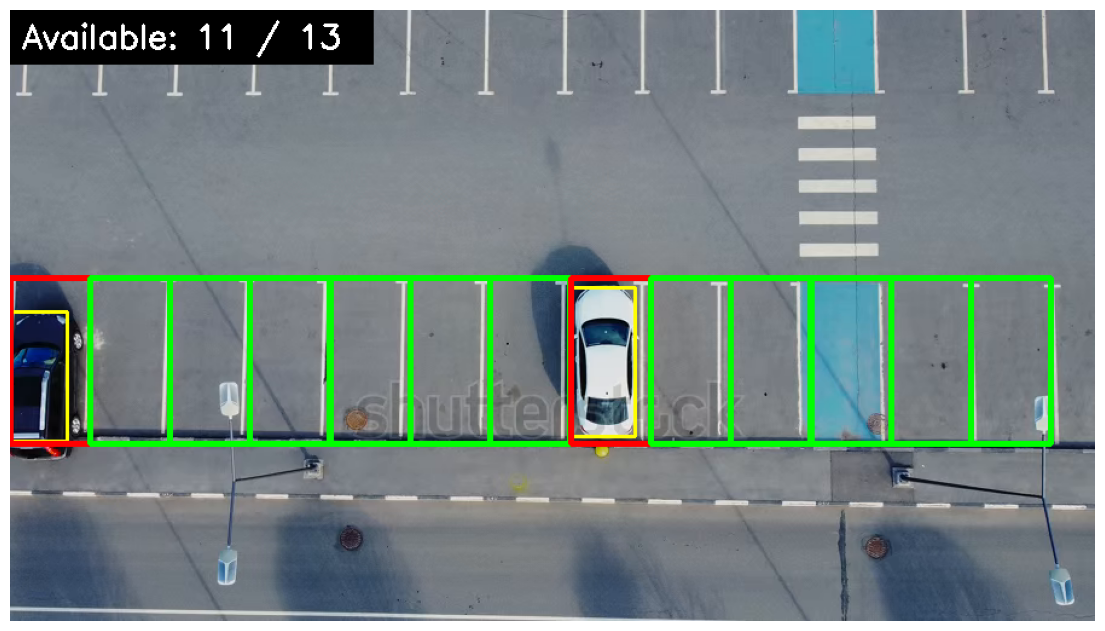

In [7]:
def overlap_ratio(spot, box):
    sx1, sy1 = spot
    sx2, sy2 = sx1 + W, sy1 + H
    bx1, by1, bx2, by2 = box
    iw = max(0, min(sx2, bx2) - max(sx1, bx1))
    ih = max(0, min(sy2, by2) - max(sy1, by1))
    return (iw * ih) / (W * H)

def spot_status(boxes):
    return [any(overlap_ratio(s, b) > OVERLAP_THR for b in boxes) for s in spots]

def draw_result(frame, boxes, occupied):
    for (x1, y1, x2, y2) in boxes:
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 255), 2)
    for (x, y), occ in zip(spots, occupied):
        color = (0, 0, 255) if occ else (0, 255, 0)
        cv2.rectangle(frame, (x, y), (x + W, y + H), color, 3)
    free = len(spots) - sum(occupied)
    cv2.rectangle(frame, (0, 0), (300, 45), (0, 0, 0), -1)
    cv2.putText(frame, f"Available: {free} / {len(spots)}", (10, 32),
                cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)
    return frame

occ0 = spot_status(boxes0)
out = draw_result(frame0.copy(), boxes0, occ0)
plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

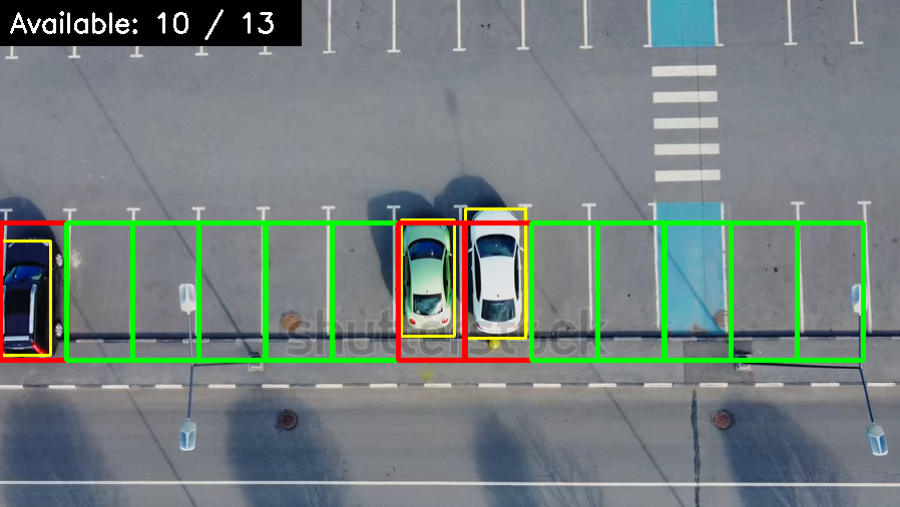

Frame 735 | Available: 10 / 13
Done, frames processed: 737


In [10]:
if path.lower().endswith(VIDEO_EXT):
    video_path = path
else:
    up = files.upload()
    video_path = list(up.keys())[0]

SHOW_EVERY = 5
MAX_FRAMES = None

cap = cv2.VideoCapture(video_path)
history = [deque(maxlen=SMOOTH_FRAMES) for _ in spots]

i = 0
while True:
    ok, frame = cap.read()
    if not ok or (MAX_FRAMES and i >= MAX_FRAMES):
        break

    boxes = detect_vehicles(frame)
    raw_occ = spot_status(boxes)

    occupied = []
    for h, o in zip(history, raw_occ):
        h.append(o)
        occupied.append(sum(h) > len(h) / 2)

    if i % SHOW_EVERY == 0:
        result = draw_result(frame, boxes, occupied)
        scale = 900 / result.shape[1]
        small = cv2.resize(result, None, fx=scale, fy=scale)
        clear_output(wait=True)
        cv2_imshow(small)
        print(f"Frame {i} | Available: {len(spots) - sum(occupied)} / {len(spots)}")

    i += 1

cap.release()
print("Done, frames processed:", i)